<a href="https://colab.research.google.com/github/diloo11/PCVK_Ganjil_2026/blob/main/Week5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob

<BarContainer object of 256 artists>

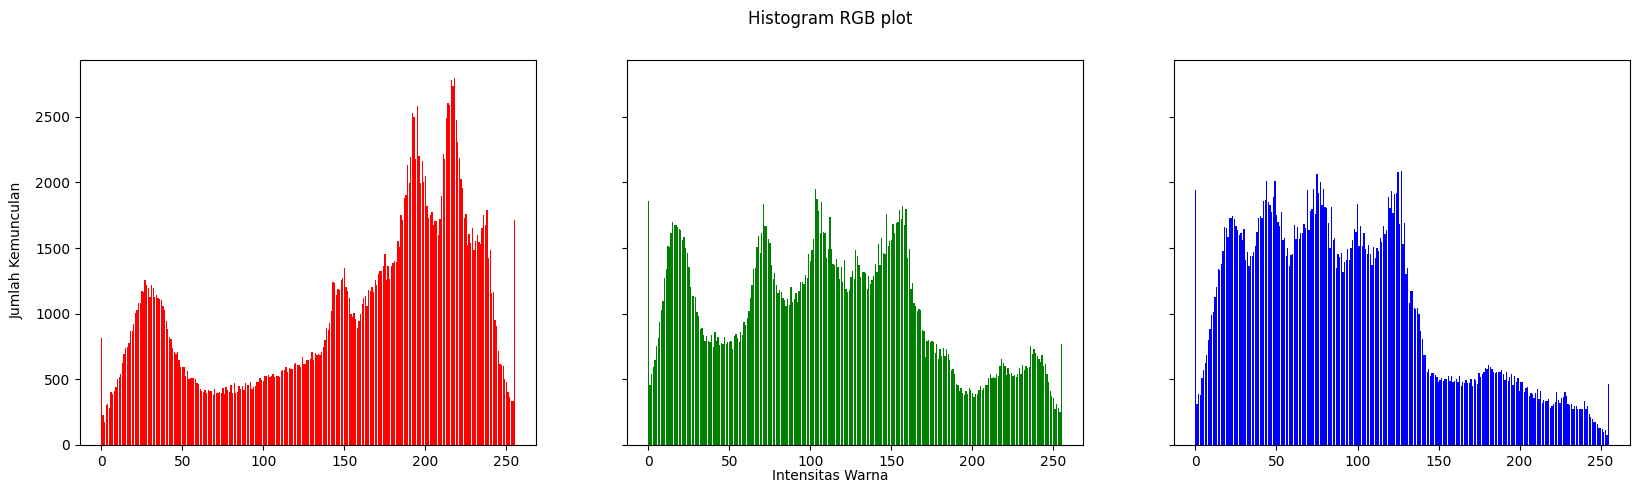

In [7]:
#membuat histogram image (manual)
img = cv.imread('/content/drive/MyDrive/lena.jpg')
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

height, width, depth = np.shape(img)
names = np.arange(256)

red = [0]*256
green = [0]*256
blue = [0]*256

for y in range (0,height) :
  for x in range (0,width) :
    red[img[y,x,0]] += 1
    green[img[y,x,1]] += 1
    blue[img[y,x,2]] += 1

names = np.arange(256)
fig, axs = plt.subplots(1, 3, figsize=[20, 5], sharex=True, sharey=True)
fig.suptitle('Histogram RGB plot')
fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
axs[0].bar(names, red, color='red')
axs[1].bar(names, green, color='green')
axs[2].bar(names, blue, color='blue')

PERTANYAAN PRAKTIKUM E1

In [26]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# Definisi Path Sesuai Ketentuan Modul
# Ubah NIM dengan NIM Anda (contoh: '2241720000')
NIM = '244107020229'
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'

def compare_histograms(image_path, title_prefix):
    # Load citra
    img = cv.imread(image_path)
    if img is None:
        print(f"Gambar tidak ditemukan di: {image_path}")
        return

    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    height, width, _ = img_rgb.shape

    # 1. Histogram Manual
    red_m = [0] * 256
    green_m = [0] * 256
    blue_m = [0] * 256

    for y in range(height):
        for x in range(width):
            red_m[img_rgb[y, x, 0]] += 1
            green_m[img_rgb[y, x, 1]] += 1
            blue_m[img_rgb[y, x, 2]] += 1

    hist_manual = np.array([red_m, green_m, blue_m], dtype=np.int64)

    # 2. np.histogram
    red_np, _ = np.histogram(img_rgb[:, :, 0], bins=256, range=[0, 256])
    green_np, _ = np.histogram(img_rgb[:, :, 1], bins=256, range=[0, 256])
    blue_np, _ = np.histogram(img_rgb[:, :, 2], bins=256, range=[0, 256])

    hist_numpy = np.array([red_np, green_np, blue_np], dtype=np.int64)

    # 3. cv2.calcHist
    red_cv = cv.calcHist([img_rgb], [0], None, [256], [0, 256]).flatten()
    green_cv = cv.calcHist([img_rgb], [1], None, [256], [0, 256]).flatten()
    blue_cv = cv.calcHist([img_rgb], [2], None, [256], [0, 256]).flatten()

    hist_cv = np.array([red_cv, green_cv, blue_cv], dtype=np.int64)

    # Menghitung Selisih Maksimum
    diff_manual_np = np.max(np.abs(hist_manual - hist_numpy))
    diff_np_cv = np.max(np.abs(hist_numpy - hist_cv))
    diff_manual_cv = np.max(np.abs(hist_manual - hist_cv))

    print(f"=== Pembuktian Selisih Maksimum [{title_prefix} - NIM: {NIM}] ===")
    print(f"Selisih Maksimum (Manual vs NumPy) : {diff_manual_np}")
    print(f"Selisih Maksimum (NumPy vs OpenCV) : {diff_np_cv}")
    print(f"Selisih Maksimum (Manual vs OpenCV): {diff_manual_cv}")
    print("-" * 50)

# Uji Coba Tahap 1: lena.jpg
compare_histograms(os.path.join(CONTOH, 'lena.jpg'), 'Tahap 1: Lena')

# Uji Coba Tahap 2: KTM1b.jpg
compare_histograms(os.path.join(BASE, 'KTM.jpeg'), 'Tahap 2: KTM1b')

=== Pembuktian Selisih Maksimum [Tahap 1: Lena - NIM: 244107020229] ===
Selisih Maksimum (Manual vs NumPy) : 0
Selisih Maksimum (NumPy vs OpenCV) : 0
Selisih Maksimum (Manual vs OpenCV): 0
--------------------------------------------------
=== Pembuktian Selisih Maksimum [Tahap 2: KTM1b - NIM: 244107020229] ===
Selisih Maksimum (Manual vs NumPy) : 0
Selisih Maksimum (NumPy vs OpenCV) : 0
Selisih Maksimum (Manual vs OpenCV): 0
--------------------------------------------------


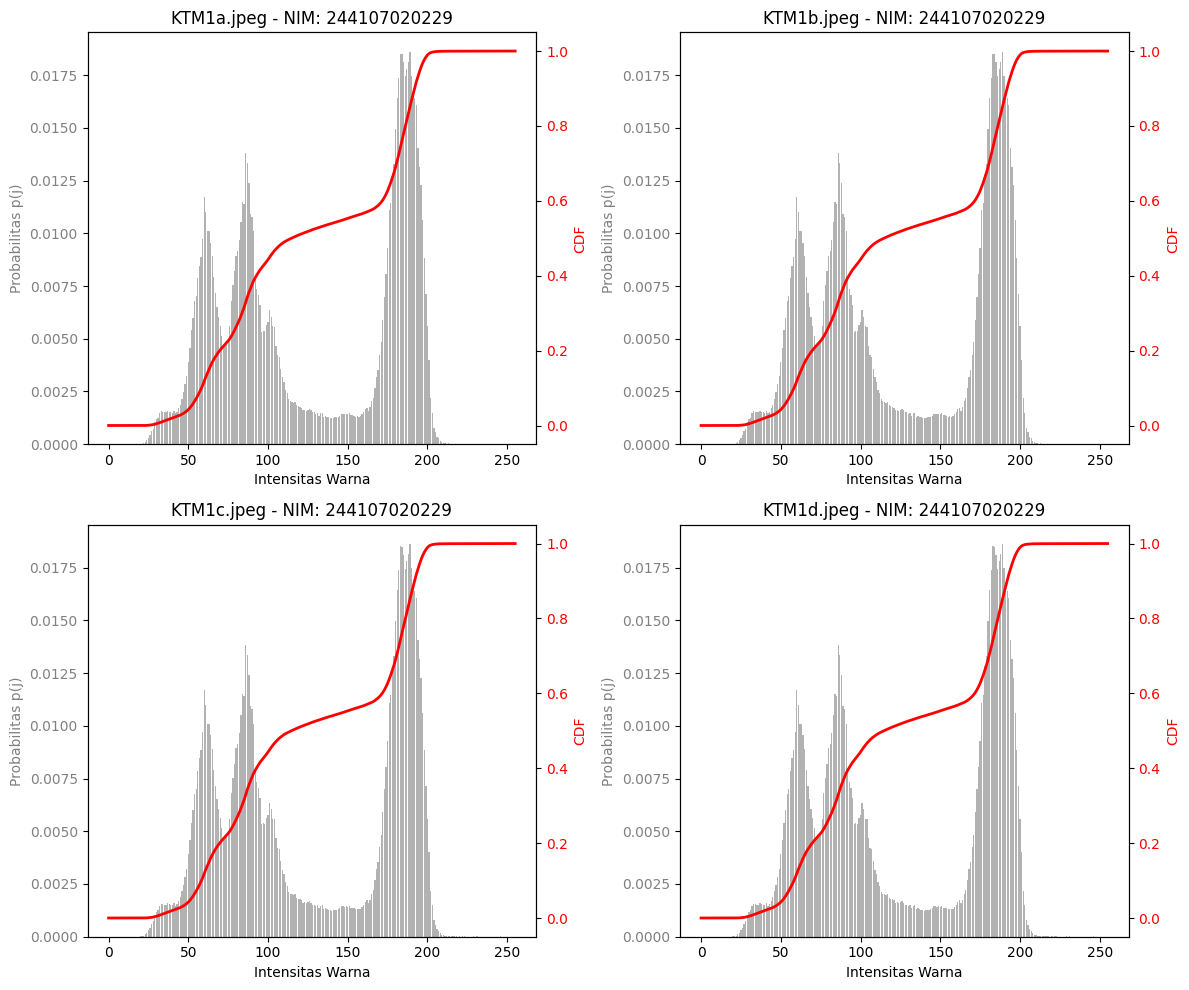

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ktm_list = ['KTM1a.jpeg', 'KTM1b.jpeg', 'KTM1c.jpeg', 'KTM1d.jpeg']

for idx, ktm_file in enumerate(ktm_list):
    ax1 = axes[idx // 2, idx % 2]
    img_path = os.path.join(BASE, ktm_file)
    img = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

    if img is None:
        ax1.set_title(f"{ktm_file} (File Not Found)")
        continue

    # 1. Compute Normalized Histogram p(j)
    hist, _ = np.histogram(img.flatten(), bins=256, range=[0, 256])
    p_j = hist / hist.sum()

    # 2. Compute Cumulative Distribution Function (CDF)
    cdf = p_j.cumsum()

    # Plot Histogram Ternormalisasi p(j)
    ax1.bar(range(256), p_j, color='gray', alpha=0.6, label='Normalized Hist p(j)')
    ax1.set_xlabel('Intensitas Warna')
    ax1.set_ylabel('Probabilitas p(j)', color='gray')
    ax1.tick_params(axis='y', labelcolor='gray')

    # Plot Kurva CDF pada Sumbu Y Kedua
    ax2 = ax1.twinx()
    ax2.plot(range(256), cdf, color='red', linewidth=2, label='CDF')
    ax2.set_ylabel('CDF', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    ax1.set_title(f"{ktm_file} - NIM: {NIM}")

plt.tight_layout()
plt.show()

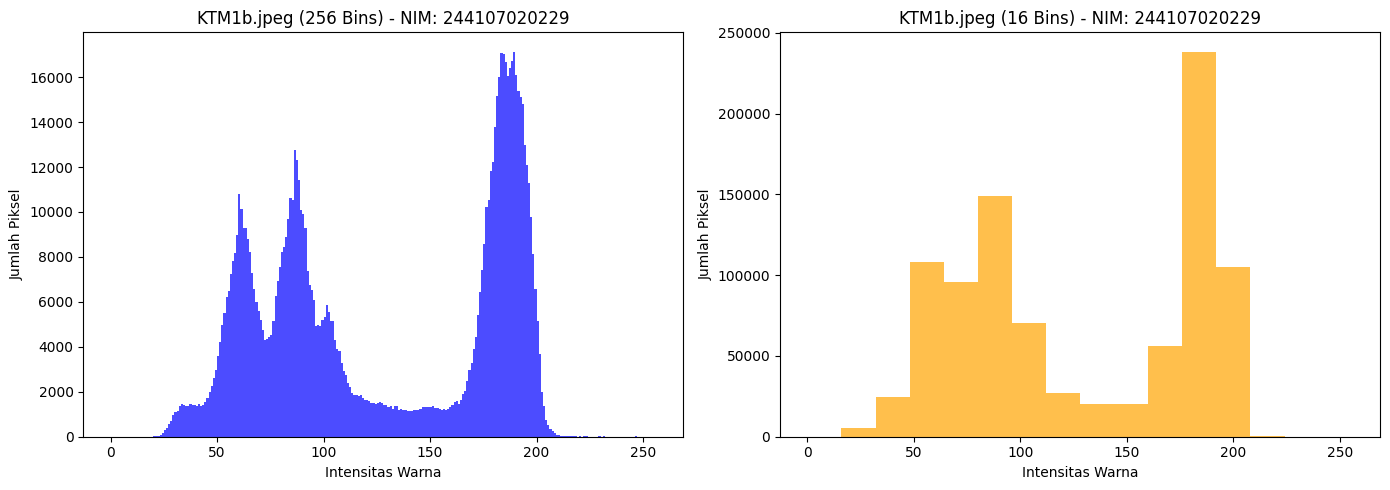

In [31]:
# Tentukan nilai PARAM['bins'], misal: 16, 32, atau 64
PARAM = {'bins': 16}

img_ktm1b = cv.imread(os.path.join(BASE, 'KTM1b.jpeg'), cv.IMREAD_GRAYSCALE)

if img_ktm1b is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # 1. Histogram 256 Bin
    axes[0].hist(img_ktm1b.flatten(), bins=256, range=[0, 256], color='blue', alpha=0.7)
    axes[0].set_title(f"KTM1b.jpeg (256 Bins) - NIM: {NIM}")
    axes[0].set_xlabel("Intensitas Warna")
    axes[0].set_ylabel("Jumlah Piksel")

    # 2. Histogram PARAM['bins'] Bin
    axes[1].hist(img_ktm1b.flatten(), bins=PARAM['bins'], range=[0, 256], color='orange', alpha=0.7)
    axes[1].set_title(f"KTM1b.jpeg ({PARAM['bins']} Bins) - NIM: {NIM}")
    axes[1].set_xlabel("Intensitas Warna")
    axes[1].set_ylabel("Jumlah Piksel")

    plt.tight_layout()
    plt.show()

E-2 PERCOBAAN HISTOGRAM EQUALIZATION

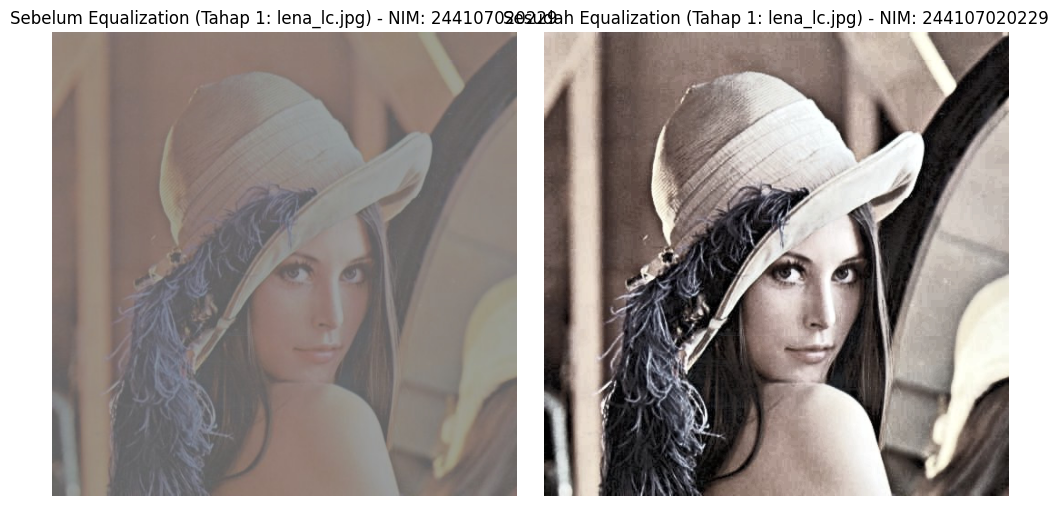

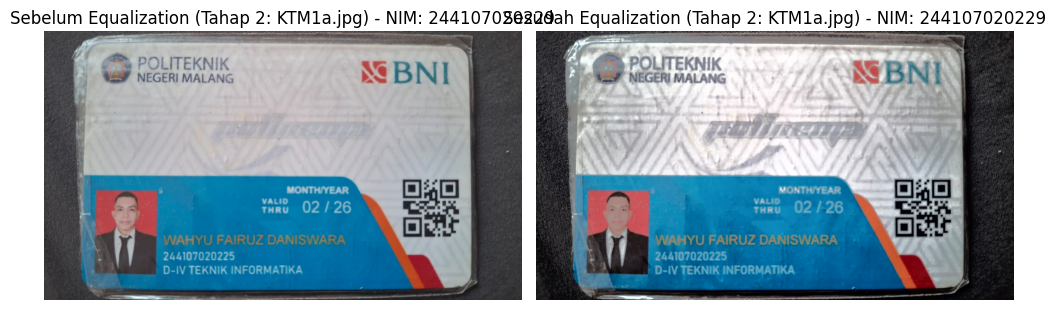

In [34]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Konfigurasi Path & NIM
NIM = '244107020229'
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'

def histogram_equalization_color(image_path, title_prefix):
    # Load citra
    img = cv.imread(image_path)
    if img is None:
        print(f"Gambar tidak ditemukan di: {image_path}")
        return

    # Convert ke RGB untuk visualisasi Matplotlib
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Convert ke ruang warna YCrCb untuk melakukan Equalization pada Kanal Luminansi (Y)
    # Pendekatan ini menjaga konsistensi warna agar tidak distorsi
    img_ycrcb = cv.cvtColor(img, cv.COLOR_BGR2YCrCb)

    # Lakukan histogram equalization pada saluran Y (luminance)
    img_ycrcb[:, :, 0] = cv.equalizeHist(img_ycrcb[:, :, 0])

    # Convert kembali ke BGR lalu ke RGB
    img_equalized_bgr = cv.cvtColor(img_ycrcb, cv.COLOR_YCrCb2BGR)
    img_equalized_rgb = cv.cvtColor(img_equalized_bgr, cv.COLOR_BGR2RGB)

    # Visualisasi Hasil: Sebelum dan Sesudah
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Sebelum Histogram Equalization
    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Sebelum Equalization ({title_prefix}) - NIM: {NIM}")
    axes[0].axis('off')

    # Sesudah Histogram Equalization
    axes[1].imshow(img_equalized_rgb)
    axes[1].set_title(f"Sesudah Equalization ({title_prefix}) - NIM: {NIM}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# ==========================================
# Tahap 1: Verifikasi dengan citra lena_lc.jpg
# ==========================================
histogram_equalization_color(os.path.join(CONTOH, 'lena_lc.jpg'), 'Tahap 1: lena_lc.jpg')

# ==========================================
# Tahap 2: Penerapan pada citra KTM1a.jpg
# ==========================================
histogram_equalization_color(os.path.join(BASE, 'KTM1a.jpeg'), 'Tahap 2: KTM1a.jpg')

In [37]:
import cv2 as cv
import numpy as np
import os

# Konfigurasi Path & NIM
NIM = '244107020229'  # Ganti dengan NIM Anda
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'

def manual_histogram_equalization_channel(channel):
    """
    Fungsi Histogram Equalization Manual untuk 1 channel (8-bit grayscale).
    Formula: h(v) = round( (cdf(v) - cdf_min) / (total_pixels - cdf_min) * 255 )
    """
    # 1. Hitung histogram
    hist, _ = np.histogram(channel.flatten(), 256, [0, 256])

    # 2. Hitung CDF
    cdf = hist.cumsum()

    # 3. Masking nilai 0 pada CDF agar nilai minimum yang diambil bukan 0
    cdf_m = np.ma.masked_equal(cdf, 0)

    # 4. Aplikasikan rumus transformasi/equalization
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())

    # 5. Kembalikan nilai 0 yang di-mask serta bulatkan nilainya
    cdf_final = np.ma.filled(cdf_m, 0).astype('uint8')

    # 6. Mappikan nilai pixel lama ke nilai equalization baru
    return cdf_final[channel]

def compare_equalize_hist(image_path, title_prefix):
    # Load citra (format BGR)
    image = cv.imread(image_path)
    if image is None:
        print(f"Gambar tidak ditemukan di: {image_path}")
        return

    # --- 1. Menggunakan cv2.equalizeHist per Channel B, G, R ---
    b, g, r = cv.split(image)

    b_equalized = cv.equalizeHist(b)
    g_equalized = cv.equalizeHist(g)
    r_equalized = cv.equalizeHist(r)

    img_cv_equalized = cv.merge([b_equalized, g_equalized, r_equalized])

    # --- 2. Menggunakan Implementasi Manual per Channel B, G, R ---
    b_manual = manual_histogram_equalization_channel(b)
    g_manual = manual_histogram_equalization_channel(g)
    r_manual = manual_histogram_equalization_channel(r)

    img_manual_equalized = cv.merge([b_manual, g_manual, r_manual])

    # --- 3. Menghitung Selisih Maksimum ---
    diff_b = np.max(np.abs(b_equalized.astype(np.int16) - b_manual.astype(np.int16)))
    diff_g = np.max(np.abs(g_equalized.astype(np.int16) - g_manual.astype(np.int16)))
    diff_r = np.max(np.abs(r_equalized.astype(np.int16) - r_manual.astype(np.int16)))

    max_diff_total = max(diff_b, diff_g, diff_r)

    print(f"=== Pembuktian Selisih Maksimum [{title_prefix}] ===")
    print(f"Selisih Maksimum Channel Blue  : {diff_b}")
    print(f"Selisih Maksimum Channel Green : {diff_g}")
    print(f"Selisih Maksimum Channel Red   : {diff_r}")
    print(f"Selisih Maksimum Total         : {max_diff_total}")
    print("-" * 55)

# Eksekusi untuk lena_lc.jpg
compare_equalize_hist(os.path.join(CONTOH, 'lena_lc.jpg'), 'Tahap 1: lena_lc.jpg')

# Eksekusi untuk KTM1a.jpg
compare_equalize_hist(os.path.join(BASE, 'KTM1a.jpeg'), 'Tahap 2: KTM1a.jpg')

=== Pembuktian Selisih Maksimum [Tahap 1: lena_lc.jpg] ===
Selisih Maksimum Channel Blue  : 1
Selisih Maksimum Channel Green : 1
Selisih Maksimum Channel Red   : 1
Selisih Maksimum Total         : 1
-------------------------------------------------------
=== Pembuktian Selisih Maksimum [Tahap 2: KTM1a.jpg] ===
Selisih Maksimum Channel Blue  : 1
Selisih Maksimum Channel Green : 1
Selisih Maksimum Channel Red   : 1
Selisih Maksimum Total         : 1
-------------------------------------------------------


Selisih angka 1 tersebut terjadi akibat perbedaan cara pembulatan nilai desimal antara Python (manual) dan library OpenCV. Python menggunakan pembulatan standar floating-point, sedangkan OpenCV menggunakan rumus pembulatan internal C++ yang lebih cepat, sehingga piksel yang nilainya berada di batas pas (seperti x.5) membulat ke angka yang berbeda selisih 1

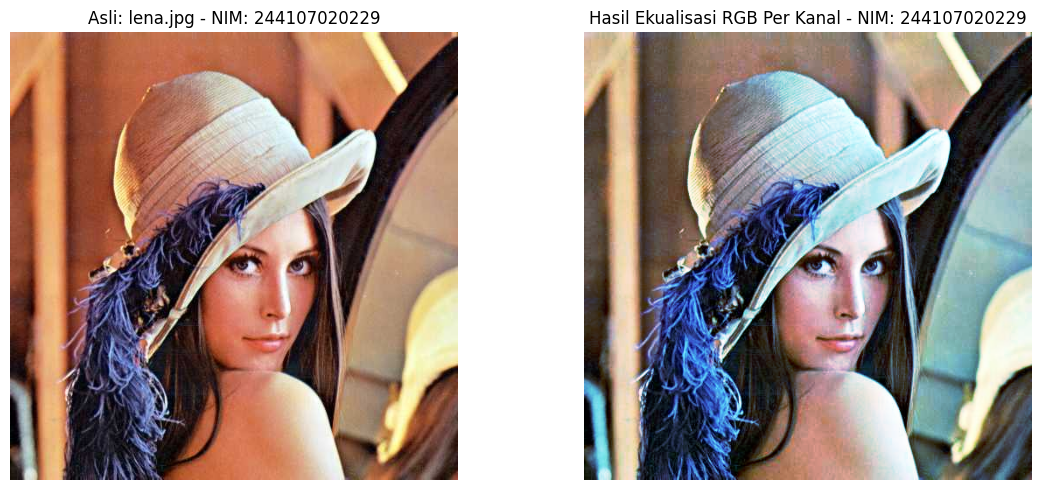

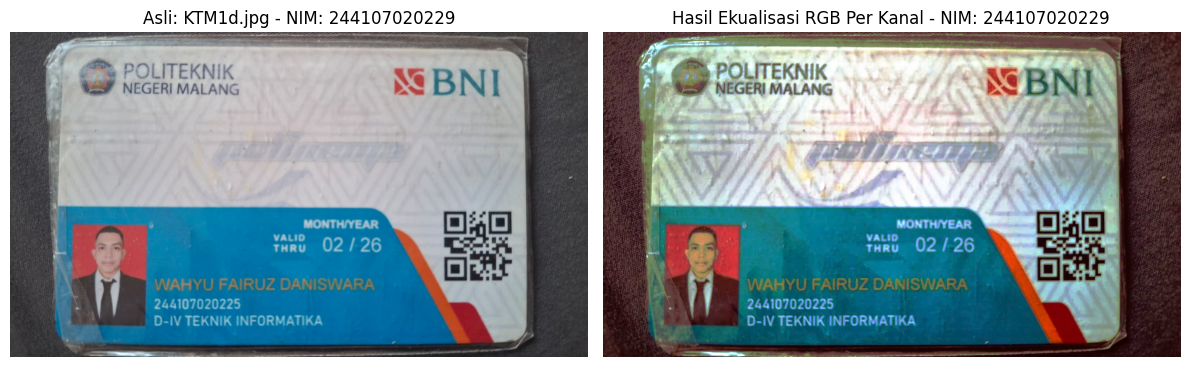

In [39]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# Konfigurasi Path & NIM
NIM = '244107020229'  # Ganti dengan NIM Anda
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'

def ekualisasi_per_kanal(path_gambar, judul):
    bgr = cv.imread(path_gambar)
    if bgr is None:
        print(f"Gambar tidak ditemukan: {path_gambar}")
        return

    # Cara 1: Tiap kanal diekualisasi sendiri-sendiri (seperti potongan kode)
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])

    # Hasil merge masih BGR, konversi ke RGB untuk ditampilkan Matplotlib
    he_bgr = cv.merge(kanal)
    he_rgb = cv.cvtColor(he_bgr, cv.COLOR_BGR2RGB)

    # Gambar asli konversi ke RGB
    asli_rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)

    # Tampilkan perbandingan
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(asli_rgb)
    axes[0].set_title(f"Asli: {judul} - NIM: {NIM}")
    axes[0].axis('off')

    axes[1].imshow(he_rgb)
    axes[1].set_title(f"Hasil Ekualisasi RGB Per Kanal - NIM: {NIM}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

# Tahap 1: Gunakan citra contoh lena.jpg
ekualisasi_per_kanal(os.path.join(CONTOH, 'lena.jpg'), 'lena.jpg')

# Tahap 2: Gunakan citra KTM1d.jpg milik Anda
ekualisasi_per_kanal(os.path.join(BASE, 'KTM1d.jpeg'), 'KTM1d.jpg')

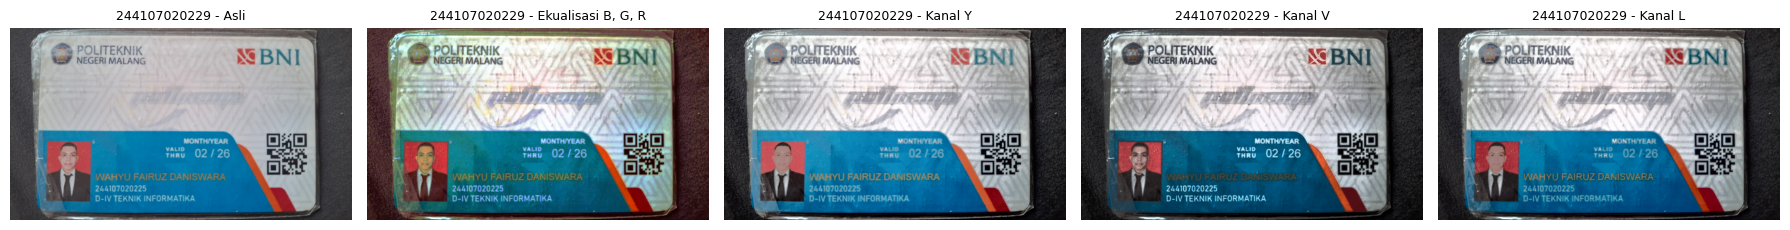

Cara                    geser Hue (der)    rerata terang
----------------------------------------------------------
Asli                               0.00            127.6
Ekualisasi B, G, R                45.86            125.0
Kanal Y                            0.35            129.0
Kanal V                            3.39            112.9
Kanal L                            8.41            120.7

=== Perbandingan CLAHE vs Ekualisasi Biasa (Kanal Y) ===
Metode                  geser Hue (der)    rerata terang
----------------------------------------------------------
Ekualisasi Biasa (Y)               0.35            129.0
CLAHE (Y)                          0.14            132.4


In [42]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# Konfigurasi Path & NIM
NIM = '244107020229'  # Ganti dengan NIM Anda
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'

# Load citra KTM1d.jpg milik Anda
berkas = os.path.join(BASE, 'KTM1d.jpeg')
bgr = cv.imread(berkas)

if bgr is None:
    print(f"Gambar tidak ditemukan di: {berkas}")
else:
    # 1. Ekualisasi per kanal (B, G, R)
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # 2. Kanal Y (YCrCb)
    ycrcb = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    # 3. Kanal V (HSV)
    hsv = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    # 4. Kanal L (LAB)
    lab = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b_lab = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b_lab]), cv.COLOR_LAB2BGR)

    # List judul dan citra
    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    # Visualisasi 5 Citra Berdampingan
    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(f"{NIM} - {t}", fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Fungsi Pergeseran Hue
    def geser_hue(asli, hasil):
        h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
        h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
        d = np.abs(h1 - h2)
        d = np.minimum(d, 180 - d)  # Hue melingkar 0-179
        return d.mean()

    # Cetak Hasil Ukuran Quantitative
    print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
    print('-' * 58)
    for t, c in zip(judul, citra):
        print('%-22s %16.2f %16.1f' % (
            t,
            geser_hue(bgr, c) * 2,
            cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()
        ))
# Parameter CLAHE
PARAM = {'clip': 2.0, 'tile': 8}

# Terapkan CLAHE pada Kanal Y (YCrCb)
clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
he_y_clahe = cv.cvtColor(cv.merge([clahe.apply(y), cr, cb]), cv.COLOR_YCrCb2BGR)

print("\n=== Perbandingan CLAHE vs Ekualisasi Biasa (Kanal Y) ===")
print('%-22s %16s %16s' % ('Metode', 'geser Hue (der)', 'rerata terang'))
print('-' * 58)
print('%-22s %16.2f %16.1f' % ('Ekualisasi Biasa (Y)', geser_hue(bgr, he_y) * 2, cv.cvtColor(he_y, cv.COLOR_BGR2GRAY).mean()))
print('%-22s %16.2f %16.1f' % ('CLAHE (Y)', geser_hue(bgr, he_y_clahe) * 2, cv.cvtColor(he_y_clahe, cv.COLOR_BGR2GRAY).mean()))

1. Ekualisasi Kanal B, G, R menghasilkan pergeseran Hue paling besar. (Isi nilai derajatnya sesuai angka tabel keluaran program Colab Anda, umumnya di atas 20°-40°). Hal ini terjadi karena perubahan independen pada kanal B, G, dan R merusak rasio proporsi warna dasar.
2. Meskipun hanya kanal terang ($Y$, $V$, atau $L$) yang diubah, konversi kembali ke ruang warna BGR melibatkan perhitungan matematika floating-point. Ketika nilainya dikonversi balik ke integer 8-bit (uint8), terjadi pembulatan (rounding) dan pemotongan nilai (clipping) pada nilai yang berada di luar rentang $[0, 255]$. Hal ini menggeser tipis komposisi warna $RGB$ awal sehingga nilai $Hue$ ikut berubah sedikit.
3. Alasan: Kedua ruang warna ini memisahkan komponen kecerahan secara perseptual lebih alami dibanding $HSV$
Dasar Penilaian: Perhatikan area pasfoto dan teks identitas KTM. Kanal $Y$/$L$ meningkatkan kontras teks agar mudah dibaca tanpa membuat warna kulit pada pasfoto terlihat kelewat jenuh (over-saturated) atau pecah (harsh contrast).  
4. Pergeseran Hue: CLAHE menghasilkan pergeseran Hue yang lebih kecil (lebih menjaga keaslian warna) dibanding ekualisasi biasa.
Rerata Kecerahan: CLAHE menghasilkan tingkat kecerahan yang lebih seimbang dan natural.

PERTANYAAN PRAKTIKUM E2

/tmp/ipykernel_1244/3718974567.py:35: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 0].hist(img.flatten(), 256, [0, 256], color='blue')
/tmp/ipykernel_1244/3718974567.py:38: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  axes[1, 1].hist(img_eq.flatten(), 256, [0, 256], color='orange')


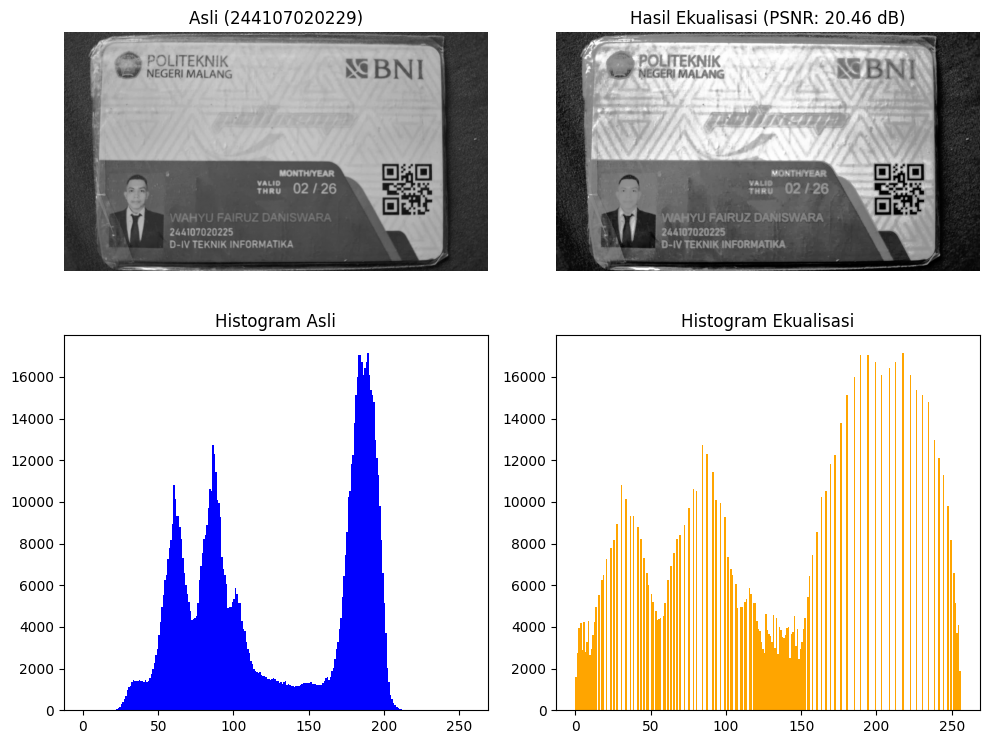

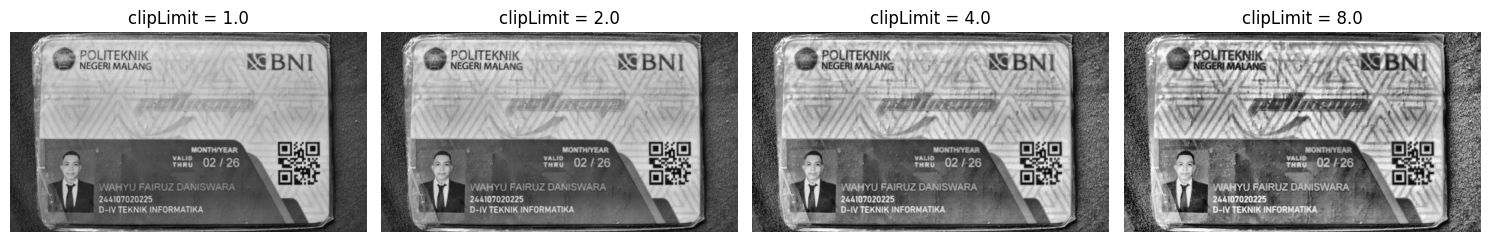

In [43]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

NIM = '244107020229'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'
PARAM = {'clip': 2.0, 'tile': 8}

# Load citra KTM1a.jpg (grayscale)
img = cv.imread(os.path.join(BASE, 'KTM1a.jpeg'), cv.IMREAD_GRAYSCALE)

# --- SOAL 1: Ekualisasi Global ---
# Manual & cv2.equalizeHist
hist, _ = np.histogram(img.flatten(), 256, [0, 256])
cdf = hist.cumsum()
cdf_m = np.ma.masked_equal(cdf, 0)
cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
img_manual = np.ma.filled(cdf_m, 0).astype('uint8')[img]
img_eq = cv.equalizeHist(img)

# Hitung PSNR
psnr_val = cv.PSNR(img, img_eq)

# Visualisasi Soal 1
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title(f'Asli ({NIM})')
axes[0, 0].axis('off')

axes[0, 1].imshow(img_eq, cmap='gray')
axes[0, 1].set_title(f'Hasil Ekualisasi (PSNR: {psnr_val:.2f} dB)')
axes[0, 1].axis('off')

axes[1, 0].hist(img.flatten(), 256, [0, 256], color='blue')
axes[1, 0].set_title('Histogram Asli')

axes[1, 1].hist(img_eq.flatten(), 256, [0, 256], color='orange')
axes[1, 1].set_title('Histogram Ekualisasi')
plt.tight_layout()
plt.show()

# --- SOAL 2: CLAHE & Variasi clipLimit ---
clahe_def = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
img_clahe = clahe_def.apply(img)

# Variasi clipLimit: 1.0, 4.0, 8.0
clips = [1.0, 2.0, 4.0, 8.0]
plt.figure(figsize=(15, 4))
for i, c_val in enumerate(clips, 1):
    c_obj = cv.createCLAHE(clipLimit=c_val, tileGridSize=(PARAM['tile'], PARAM['tile']))
    res = c_obj.apply(img)
    plt.subplot(1, 4, i)
    plt.imshow(res, cmap='gray')
    plt.title(f'clipLimit = {c_val}')
    plt.axis('off')
plt.tight_layout()
plt.show()

1. PSNR mengukur tingkat kemiripan piksel dengan citra asli (piksel identik = PSNR tinggi). Ekualisasi memicu perubahan nilai intensitas piksel secara drastis untuk merentangkan kontras, sehingga perbedaan (error) piksel dibanding citra asli sangat besar dan nilai PSNR justru turun.
Kesimpulan Keterbacaan: Tidak layak. PSNR hanya menilai kemiripan sinyal citra asli, bukan kualitas visual atau tingkat keterbacaan (human visual perception)
2.
a. Hasil Lebih Terbaca: CLAHE. Teks NIM dan nama pada KTM jauh lebih terbaca dibanding ekualisasi global karena CLAHE meningkatkan kontras secara lokal tanpa menyebabkan over-exposure pada area tertentu.

b. Nilai Terbaik & Noise: Nilai terbaik umumnya clipLimit = 2.0 (mencapai kontras optimal tanpa memunculkan bintik bintik noise). Noise mulai terlihat menonjol pada bagian latar belakang/area homogen saat clipLimit dinaikkan ke 4.0 atau 8.0.

E-3 TUGAS PRAKTIKUM DITHERING

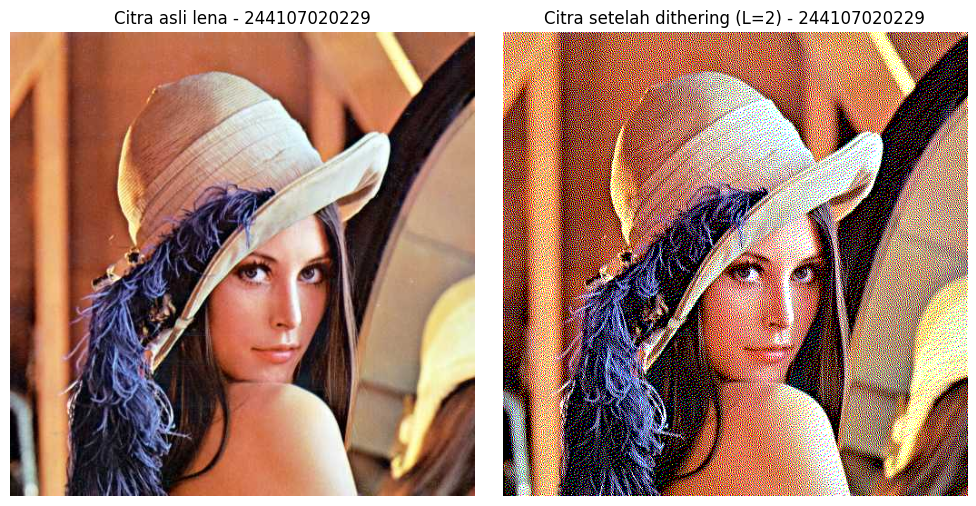

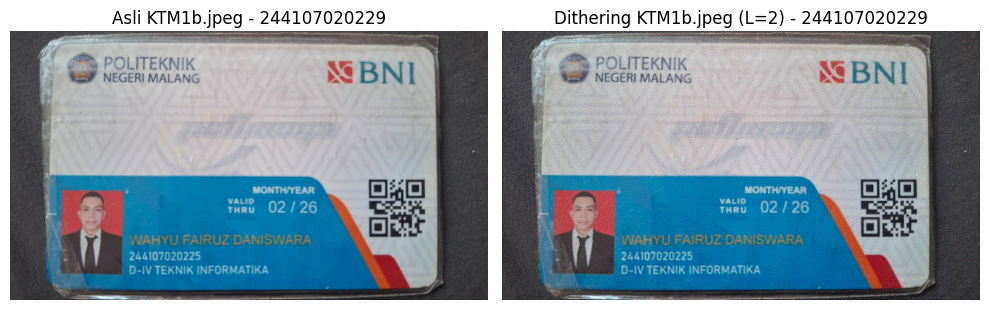

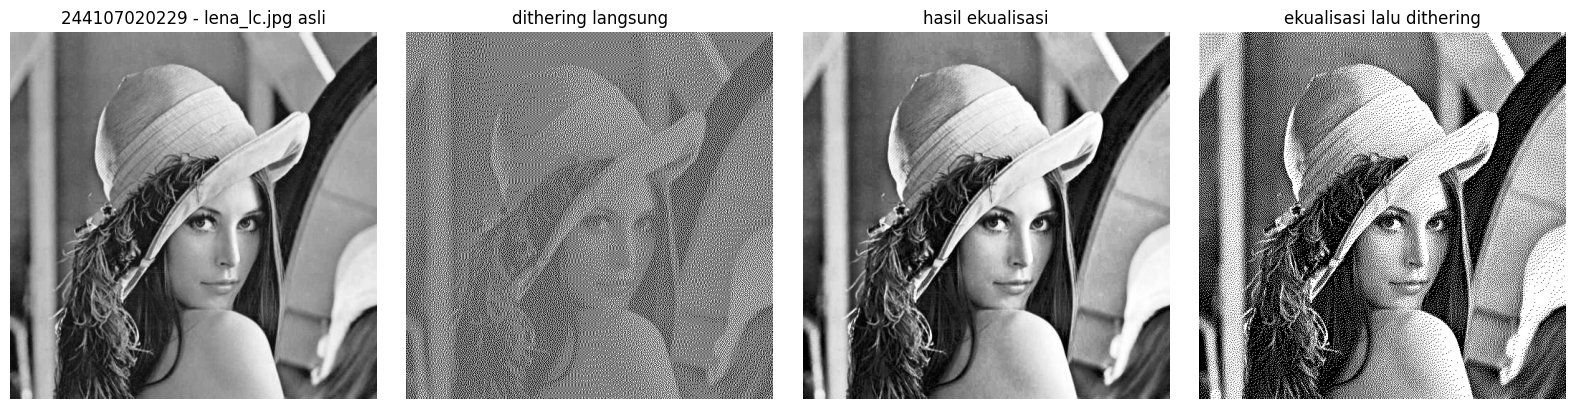

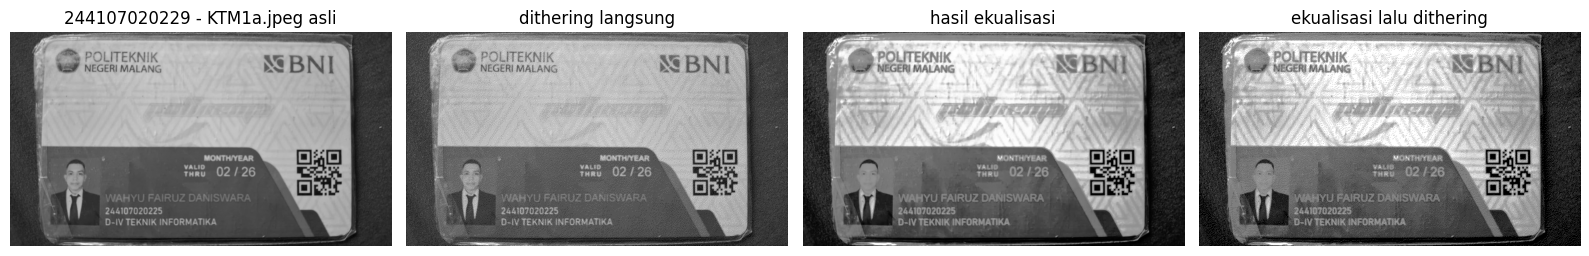

In [46]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import os

# Konfigurasi NIM dan Path
NIM = '244107020229'  # Ganti dengan NIM Anda
CONTOH = '/content/drive/MyDrive/PCVK/Images'
BASE = f'/content/drive/MyDrive/PCVK/Images/{NIM}'
PARAM = {'L': 2}  # Jumlah level kuantisasi

# ==========================================
# Fungsi Dithering Floyd-Steinberg (1 Kanal)
# ==========================================
def floyd_steinberg(gray_img, L):
    img = gray_img.astype(np.float32)
    step = 255.0 / (L - 1)
    H, W = img.shape

    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step
            img[y, x] = baru
            error = lama - baru

            if x + 1 < W:
                img[y, x + 1] += error * 7 / 16
            if x > 0 and y + 1 < H:
                img[y + 1, x - 1] += error * 3 / 16
            if y + 1 < H:
                img[y + 1, x] += error * 5 / 16
            if x + 1 < W and y + 1 < H:
                img[y + 1, x + 1] += error * 1 / 16

    img = np.clip(img, 0, 255)
    return img.astype(np.uint8)

# ==========================================
# Fungsi Dithering Berwarna (3 Kanal BGR)
# ==========================================
def floyd_steinberg_color(bgr_img, L):
    channels = cv.split(bgr_img)
    dithered_channels = [floyd_steinberg(ch, L) for ch in channels]
    return cv.merge(dithered_channels)

# ==========================================
# SOAL 1: Dithering Citra Berwarna / Grayscale
# ==========================================
# Tahap 1: lena.jpg
img_lena = cv.imread(os.path.join(CONTOH, 'lena.jpg'))
if img_lena is not None:
    lena_dither = floyd_steinberg_color(img_lena, PARAM['L'])

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img_lena, cv.COLOR_BGR2RGB))
    plt.title(f'Citra asli lena - {NIM}')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(lena_dither, cv.COLOR_BGR2RGB))
    plt.title(f'Citra setelah dithering (L={PARAM["L"]}) - {NIM}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# Tahap 2: KTM1b.jpg
img_ktm1b = cv.imread(os.path.join(BASE, 'KTM1b.jpeg'))
if img_ktm1b is not None:
    ktm_dither = floyd_steinberg_color(img_ktm1b, PARAM['L'])

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(cv.cvtColor(img_ktm1b, cv.COLOR_BGR2RGB))
    plt.title(f'Asli KTM1b.jpeg - {NIM}')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(cv.cvtColor(ktm_dither, cv.COLOR_BGR2RGB))
    plt.title(f'Dithering KTM1b.jpeg (L={PARAM["L"]}) - {NIM}')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

# ==========================================
# SOAL 2: Dithering dengan Histogram Equalization
# ==========================================
def proses_soal_2(path_img, nama_citra):
    img_gray = cv.imread(path_img, cv.IMREAD_GRAYSCALE)
    if img_gray is None:
        return

    # 1. Dithering langsung
    dither_langsung = floyd_steinberg(img_gray, PARAM['L'])

    # 2. Ekualisasi histogram
    img_eq = cv.equalizeHist(img_gray)

    # 3. Ekualisasi lalu dithering
    eq_dither = floyd_steinberg(img_eq, PARAM['L'])

    # Visualisasi 4 Gambar
    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(img_gray, cmap='gray')
    plt.title(f'{NIM} - {nama_citra} asli')
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(dither_langsung, cmap='gray')
    plt.title('dithering langsung')
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(img_eq, cmap='gray')
    plt.title('hasil ekualisasi')
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(eq_dither, cmap='gray')
    plt.title('ekualisasi lalu dithering')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Tahap 1: lena_lc.jpg
proses_soal_2(os.path.join(CONTOH, 'lena_lc.jpg'), 'lena_lc.jpg')

# Tahap 2: KTM1a.jpeg
proses_soal_2(os.path.join(BASE, 'KTM1a.jpeg'), 'KTM1a.jpeg')

2. Urutan "Ekualisasi Lalu Dithering" menghasilkan teks pada KTM yang jauh lebih jelas dan mudah dibaca dibanding dithering langsung.

Alasan:
- Citra asli ($KTM1a.jpg$) atau citra berkontras rendah (low contrast) memiliki sebaran derajat keabuan yang sempit, sehingga saat langsung di-dither ($L=2$), batas antara teks dan latar belakang menjadi samar atau tertutup pola bintik noise.  
-  Tahap Histogram Equalization memperlebar sebaran kontras terlebih dahulu secara signifikan, sehingga perbedaan nilai intensitas piksel teks dan latar belakang menjadi sangat tegas. Ketika dilanjutkan dengan dithering, pola bintik hitam-putih dapat membentuk kontur huruf/karakter dengan jauh lebih presisi.